# Phase 1 · Lesson 2: NumPy II, Randomness and Linear Algebra (the Road to PCA)
**ML Engineer Journey · Benson M. Merita**

**Goal:** learn the two NumPy toolkits that ML relies on most after basic arrays:
- **`np.random`**: reproducible randomness for shuffling, splitting, initialising weights, and simulating data you know the truth about.
- **`np.linalg`**: norms, solving, eigenvalues, SVD.

Then you combine them to build your first real unsupervised algorithm from scratch: **Principal Component Analysis (PCA)**.

| Section | What you get |
|---|---|
| 1 · Intuition | Why ML needs controlled randomness, and what PCA "sees" |
| 2 · The math | Variance maximisation → eigenvalue problem → SVD |
| 3 · From scratch | `default_rng`, simulation, `linalg`, condition numbers, a `PCA` class |
| 4 · With libraries | `sklearn.decomposition.PCA` |
| 5 · Dataset | Wine (scikit-learn built-in) |
| 6–8 | Exercises, quiz, mistakes & interview questions |
| 🎬 Demo | Rotating-axis GIF, scree plot, 3-D interactive |

---
## 1 · Intuition

**Randomness, but controlled.** ML uses randomness everywhere: shuffling data before a split, initialising a neural net's weights, bootstrapping samples for a random forest. The danger is that if every run is different, you can't tell whether a change *you* made improved the model or you just got lucky. A **seed** makes randomness repeatable: same seed, same "random" numbers, same result. Experiments in professional ML teams are expected to be reproducible.

**Simulation, your secret weapon.** If you *generate* data from a model you choose (say $y = 3x_1 - 2x_2 + \text{noise}$), you know the true answer. Then you can check whether your algorithm recovers it. This is how you test ML code when real data gives you no answer key.

**PCA in one picture.** Picture a cloud of points shaped like a rugby ball. Most of its spread lies along one long axis. PCA finds that axis (the direction of **maximum spread**), then the next-longest axis perpendicular to it, and so on. Keep the first few axes and you've compressed 13 features into 2 or 3 while keeping most of the information. Then you can **plot** 13-dimensional data.

**Real ML engineering connection:** PCA is used to compress features, remove correlated variables, speed up models, and visualise embeddings. The eigen/SVD maths here also underlies recommender systems (matrix factorisation) and the low-rank (LoRA) fine-tuning of large language models.

---
## 2 · The math

Let $Z \in \mathbb{R}^{n\times d}$ be **centred** data (column means 0). The sample covariance matrix is
$$C = \frac{1}{n-1} Z^\top Z \in \mathbb{R}^{d\times d} \quad \text{(symmetric, positive semi-definite)}$$

**Variance along a direction.** Project every sample onto a unit vector $u$: the scores are $Zu \in \mathbb{R}^n$. Their variance is
$$\operatorname{Var}(Zu) = \frac{1}{n-1}(Zu)^\top(Zu) = u^\top C u$$

**Maximise it** subject to $\lVert u\rVert = 1$, using a Lagrangian (your optimisation course):
$$\mathcal{L}(u,\lambda) = u^\top C u - \lambda(u^\top u - 1) \;\Rightarrow\; \nabla_u \mathcal{L} = 2Cu - 2\lambda u = 0 \;\Rightarrow\; \boxed{Cu = \lambda u}$$
So the stationary directions are **eigenvectors of $C$**, and at those points the variance is $u^\top C u = \lambda$. **The first principal component is the eigenvector with the largest eigenvalue.** Each later component maximises variance under an orthogonality constraint, giving the next eigenvectors (the spectral theorem guarantees an orthonormal set because $C$ is symmetric).

**Explained variance ratio** of component $k$: $\dfrac{\lambda_k}{\sum_j \lambda_j}$ (and $\sum_j\lambda_j = \operatorname{tr}(C)$ = total variance).

**Projection (the "transform")** onto the top $k$ components $W_k = [u_1,\dots,u_k] \in \mathbb{R}^{d\times k}$:
$$T = Z W_k \in \mathbb{R}^{n\times k}, \qquad \hat{Z} = T W_k^\top \text{ (reconstruction)}$$

**SVD route (what libraries actually do).** If $Z = U\Sigma V^\top$, then
$$C = \frac{1}{n-1}V\Sigma U^\top U \Sigma V^\top = V\,\frac{\Sigma^2}{n-1}\,V^\top$$
The columns of $V$ are the principal directions and $\lambda_k = \sigma_k^2/(n-1)$. SVD avoids forming $Z^\top Z$, which **squares the condition number**, so it is numerically safer.

**Condition number** $\kappa(A) = \sigma_{\max}/\sigma_{\min}$. A large $\kappa$ means nearly dependent columns, so a tiny change in data makes a huge change in the solution. That explains the unstable s1/s2 weights in Lesson 1.

---
## 3 · Code from scratch (NumPy only)
### 3.1 The modern random API: `default_rng`

In [1]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)

rng = np.random.default_rng(seed=42)      # a Generator object: pass it around, don't use global np.random.seed
print("uniform [0,1):     ", rng.random(3))
print("normal(0, 1):      ", rng.normal(0, 1, size=3))
print("integers [0,10):   ", rng.integers(0, 10, size=5))
print("choice w/o replace:", rng.choice(["A", "B", "C", "D"], size=2, replace=False))
print("permutation:       ", rng.permutation(6))

# Reproducibility: same seed -> identical stream
a = np.random.default_rng(7).normal(size=3)
b = np.random.default_rng(7).normal(size=3)
print("same seed, same numbers?", np.array_equal(a, b))

uniform [0,1):      [0.774 0.439 0.859]
normal(0, 1):       [ 0.941 -1.951 -1.302]
integers [0,10):    [7 7 7 7 5]
choice w/o replace: ['D' 'A']
permutation:        [5 0 2 4 3 1]
same seed, same numbers? True


*Use `default_rng(seed)` and pass the generator into your functions. The older `np.random.seed()` changes **global** state, so any library call in between can silently change your results.*

### 3.2 Shuffle-and-split by hand (preview of `train_test_split`)

In [2]:
n = 10
idx = rng.permutation(n)             # shuffled indices 0..9
cut = int(0.8 * n)
train_idx, test_idx = idx[:cut], idx[cut:]
print("train:", train_idx, "| test:", test_idx)
print("no overlap?", len(np.intersect1d(train_idx, test_idx)) == 0)

train: [0 9 8 4 7 2 3 5] | test: [6 1]
no overlap? True


*Shuffle the **indices**, not the arrays separately. Then `X[train_idx]` and `y[train_idx]` stay aligned. Shuffling X and y independently is a classic bug.*

### 3.3 Simulate data with a known truth, then recover it
Generate $y = 4 + 3x_1 - 2x_2 + \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, 0.5^2)$, then reuse the normal equations from Lesson 1.

In [3]:
rng = np.random.default_rng(0)
n = 500
X = rng.normal(size=(n, 2))
w_true = np.array([4.0, 3.0, -2.0])                    # [bias, w1, w2]
Xb = np.c_[np.ones(n), X]
y = Xb @ w_true + rng.normal(0, 0.5, size=n)

w_hat = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
print("true:     ", w_true)
print("estimated:", w_hat)

true:      [ 4.  3. -2.]
estimated: [ 4.027  3.018 -2.023]


*The estimates are close but not exact, because the noise limits how precisely you can recover the truth. Exercise 3 asks how the error shrinks as $n$ grows (statistics you already know: about $1/\sqrt{n}$).*

### 3.4 The `linalg` toolkit

In [4]:
A = np.array([[4.0, 1.0],
              [1.0, 3.0]])
v = np.array([3.0, 4.0])

print("L2 norm ||v||:   ", np.linalg.norm(v))            # sqrt(9+16) = 5
print("L1 norm:         ", np.linalg.norm(v, ord=1))     # 7: used in Lasso (Phase 4)
print("det(A):          ", np.linalg.det(A))
print("solve A x = v:   ", np.linalg.solve(A, v))
vals, vecs = np.linalg.eigh(A)                           # eigh: for SYMMETRIC matrices (ascending order)
print("eigenvalues:     ", vals)
print("eigenvectors (columns):\n", vecs)
print("check A u = lambda u:", np.allclose(A @ vecs[:, 1], vals[1] * vecs[:, 1]))
U, S, Vt = np.linalg.svd(A)
print("singular values: ", S, "| condition number:", np.linalg.cond(A))

L2 norm ||v||:    5.0
L1 norm:          7.0
det(A):           11.000000000000002
solve A x = v:    [0.455 1.182]
eigenvalues:      [2.382 4.618]
eigenvectors (columns):
 [[ 0.526 -0.851]
 [-0.851 -0.526]]
check A u = lambda u: True
singular values:  [4.618 2.382] | condition number: 1.938748901931751


**Intentional error: solving a singular system** (perfectly collinear columns: the second column is 2× the first):

In [5]:
S_mat = np.array([[1.0, 2.0],
                  [2.0, 4.0]])
np.linalg.solve(S_mat, np.array([1.0, 2.0]))

LinAlgError: Singular matrix

*`LinAlgError: Singular matrix`. In ML this happens when a feature duplicates another, for example both `price_ksh` and `price_usd`, or one-hot encoding every category plus an intercept (the "dummy-variable trap", Phase 2). Nearly singular is worse, because you get no error, just garbage weights. That's what the condition number detects:*

### 3.5 Diagnosing Lesson 1's unstable weights with the condition number

In [6]:
from sklearn.datasets import load_diabetes
d = load_diabetes(scaled=False)
Zd = (d.data - d.data.mean(0)) / d.data.std(0)
print("condition number, all 10 features:", round(np.linalg.cond(Zd), 1))
keep = [i for i, f in enumerate(d.feature_names) if f != "s1"]
print("condition number, without s1:     ", round(np.linalg.cond(Zd[:, keep]), 1))
corr = np.corrcoef(Zd, rowvar=False)
i1, i2 = d.feature_names.index("s1"), d.feature_names.index("s2")
print("corr(s1, s2):", round(corr[i1, i2], 3))

condition number, all 10 features: 21.7
condition number, without s1:      6.8
corr(s1, s2): 0.897


*s1 and s2 are about 90% correlated. Dropping one cuts κ sharply. This is **multicollinearity**: the model can trade weight between s1 and s2 almost freely, so their individual weights mean little. Phase 4 fixes this with Ridge regularisation.*

---
## 5 · Practice dataset (used in 3.6 and 4)
**Wine recognition** (scikit-learn built-in, originally UCI)
- **178 wines** from **3 cultivars** grown in the same region of Italy.
- **13 chemical features:** alcohol, malic acid, ash, magnesium, flavanoids, colour intensity, proline, and more.
- **Task here (unsupervised):** compress 13 dimensions to 2–3 with PCA and see whether the cultivars separate *without ever using the labels*. (We only use the labels to colour the plot afterwards.)
- **Load:** `from sklearn.datasets import load_wine`. No download needed.

In [7]:
from sklearn.datasets import load_wine
wine = load_wine()
Xw, yw = wine.data, wine.target
print("shape:", Xw.shape, "| classes:", np.bincount(yw))
print("feature std range:", Xw.std(0).min().round(3), "to", Xw.std(0).max().round(1), "(proline)")

shape: (178, 13) | classes: [59 71 48]
feature std range: 0.124 to 314.0 (proline)


*The feature scales differ by a factor of over 1,000. PCA maximises variance, so on raw data it would simply say "proline is the main axis". **Standardise first.***

### 3.6 PCA from scratch, written in the scikit-learn `fit` / `transform` style

In [8]:
class PCAScratch:
    """PCA via eigendecomposition of the covariance matrix."""
    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        Z = X - self.mean_                                 # centre (broadcasting)
        C = Z.T @ Z / (len(Z) - 1)                         # covariance (d x d)
        vals, vecs = np.linalg.eigh(C)                     # ascending order
        order = np.argsort(vals)[::-1]                     # -> descending
        vals, vecs = vals[order], vecs[:, order]
        self.explained_variance_ = vals[: self.n_components]
        self.explained_variance_ratio_ = self.explained_variance_ / vals.sum()
        self.components_ = vecs[:, : self.n_components].T  # rows = directions (sklearn convention)
        return self                                        # lets you chain: PCAScratch(2).fit(X).transform(X)

    def transform(self, X):
        return (X - self.mean_) @ self.components_.T       # scores T = Z W_k

    def inverse_transform(self, T):
        return T @ self.components_ + self.mean_           # reconstruction

Zw = (Xw - Xw.mean(0)) / Xw.std(0)                         # standardise
pca_s = PCAScratch(n_components=13).fit(Zw)
print("explained variance ratio:", pca_s.explained_variance_ratio_[:5].round(3), "...")
print("cumulative:              ", np.cumsum(pca_s.explained_variance_ratio_)[:5].round(3))
print("components orthonormal?  ", np.allclose(pca_s.components_ @ pca_s.components_.T, np.eye(13)))

explained variance ratio: [0.362 0.192 0.111 0.071 0.066] ...
cumulative:               [0.362 0.554 0.665 0.736 0.802]
components orthonormal?   True


*With 2 components you keep about 55% of the variance, and 5 components get you past 80%. A `fit` that learns attributes ending in `_` and returns `self`, followed by `transform`, is exactly the scikit-learn estimator contract. You'll write classes like this again in Lesson 6.*

In [9]:
pca2 = PCAScratch(2).fit(Zw)
T = pca2.transform(Zw)
Z_rec = pca2.inverse_transform(T)
err = np.mean((Zw - Z_rec) ** 2)
print("scores shape:", T.shape)
print(f"reconstruction MSE with 2 comps: {err:.3f}  (= share of variance lost, about {1 - pca2.explained_variance_ratio_.sum():.3f})")

scores shape: (178, 2)
reconstruction MSE with 2 comps: 0.446  (= share of variance lost, about 0.446)


*Reconstruction error ≈ the variance you discarded. PCA is the **best** rank-k linear compression in the least-squares sense (Eckart–Young theorem).*

---
## 4 · The same thing with scikit-learn

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Z_sk = StandardScaler().fit_transform(Xw)
pca_sk = PCA(n_components=2).fit(Z_sk)
T_sk = pca_sk.transform(Z_sk)

print("variance ratio  sklearn:", pca_sk.explained_variance_ratio_.round(4), "| ours:", pca2.explained_variance_ratio_.round(4))
print("components equal up to sign?", np.allclose(np.abs(pca_sk.components_), np.abs(pca2.components_)))
signs = np.sign(np.sum(pca_sk.components_ * pca2.components_, axis=1))
print("sign flips per component:", signs, "-> scores match after flipping:", np.allclose(T_sk, T * signs))

variance ratio  sklearn: [0.362 0.192] | ours: [0.362 0.192]
components equal up to sign? True
sign flips per component: [-1. -1.] -> scores match after flipping: True


*Eigenvectors are only defined **up to sign** ($u$ and $-u$ both satisfy $Cu = \lambda u$). scikit-learn uses SVD and fixes a sign convention, so your axes may come out mirrored. The geometry is identical. Expect this as an interview question.*

| Your NumPy | scikit-learn |
|---|---|
| centre + `eigh(C)` + sort | `PCA().fit` (uses SVD internally) |
| `(X - mean) @ components.T` | `.transform` |
| `T @ components + mean` | `.inverse_transform` |
| `vals / vals.sum()` | `.explained_variance_ratio_` |

---
## 🎬 Demo visuals for your post
### Demo A: PCA scatter + scree plot (`assets/wine_pca.png`)

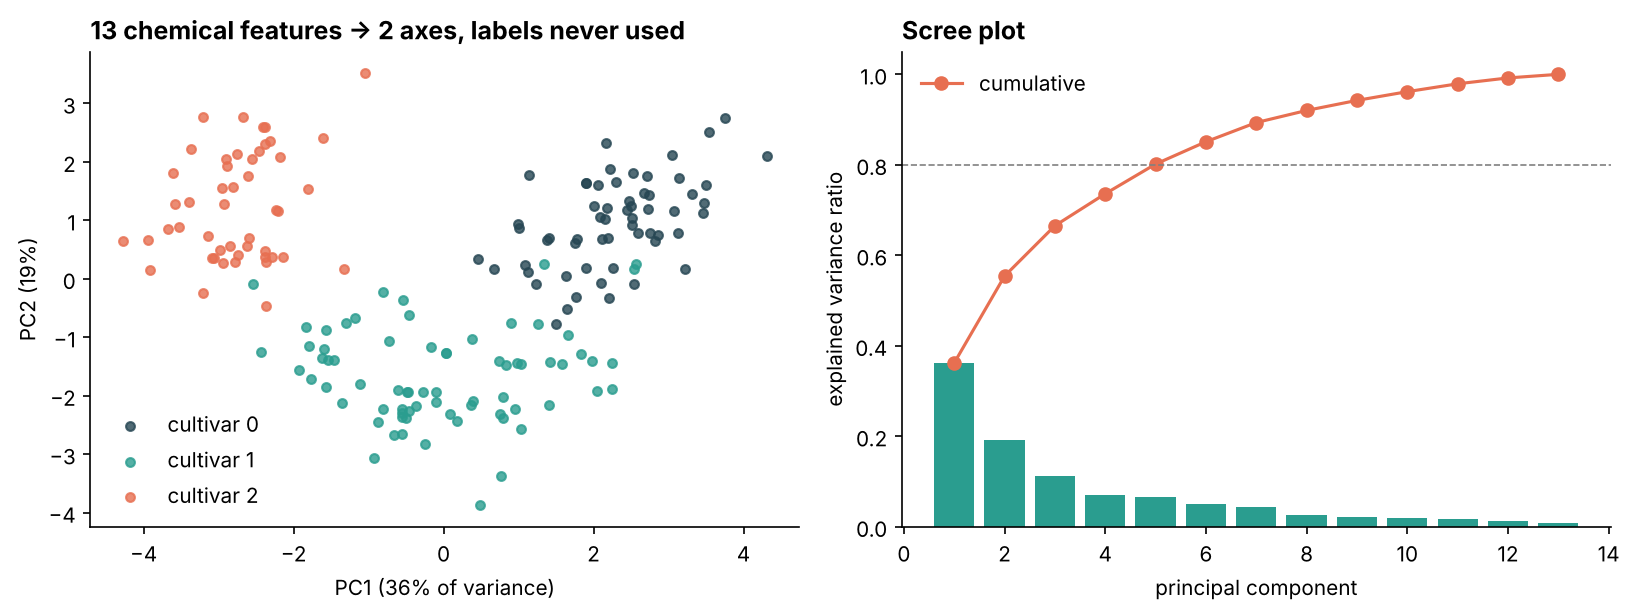

In [11]:
import matplotlib.pyplot as plt
colors = ["#264653", "#2a9d8f", "#e76f51"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
for c in range(3):
    axes[0].scatter(T_sk[yw == c, 0], T_sk[yw == c, 1], s=18, alpha=.8, color=colors[c], label=f"cultivar {c}")
axes[0].set_xlabel(f"PC1 ({pca_sk.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca_sk.explained_variance_ratio_[1]:.0%})")
axes[0].set_title("13 chemical features -> 2 axes, labels never used", loc="left", fontweight="bold")
axes[0].legend(frameon=False)
r = pca_s.explained_variance_ratio_
axes[1].bar(range(1, 14), r, color="#2a9d8f")
axes[1].plot(range(1, 14), np.cumsum(r), "o-", color="#e76f51", label="cumulative")
axes[1].axhline(0.8, ls="--", lw=.8, color="grey")
axes[1].set_xlabel("principal component"); axes[1].set_ylabel("explained variance ratio")
axes[1].set_title("Scree plot", loc="left", fontweight="bold"); axes[1].legend(frameon=False)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("assets/wine_pca.png", bbox_inches="tight"); plt.show()

### Demo B: "the eigenvector wins" GIF (`assets/rotating_axis.gif`)
A line rotates through 2-D data while a bar shows the variance of the projected points. The variance peaks exactly at PC1. That's the Lagrangian result, animated. This makes a strong hook for your video.

In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter
P = StandardScaler().fit_transform(Xw[:, [wine.feature_names.index("flavanoids"), wine.feature_names.index("total_phenols")]])
C2 = np.cov(P, rowvar=False)
vals2, vecs2 = np.linalg.eigh(C2)
pc1_angle = np.degrees(np.arctan2(vecs2[1, -1], vecs2[0, -1])) % 180
angles = np.linspace(0, 180, 90, endpoint=False)
var_at = [np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]) @ C2 @ np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]) for a in angles]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 4.2), dpi=100, gridspec_kw={"width_ratios": [1, 1.2]})
def update(k):
    a = np.radians(angles[k]); u = np.array([np.cos(a), np.sin(a)])
    proj = np.outer(P @ u, u)
    ax.clear(); bx.clear()
    ax.scatter(P[:, 0], P[:, 1], s=10, alpha=.4, color="#264653")
    ax.scatter(proj[:, 0], proj[:, 1], s=8, color="#e76f51")
    ax.plot([-4 * u[0], 4 * u[0]], [-4 * u[1], 4 * u[1]], color="#e76f51", lw=2)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal")
    ax.set_title(f"direction u at {angles[k]:.0f} deg", loc="left")
    bx.plot(angles, var_at, color="#264653")
    bx.axvline(pc1_angle, ls="--", color="grey"); bx.text(pc1_angle + 2, min(var_at), "PC1", color="grey")
    bx.scatter([angles[k]], [var_at[k]], s=60, color="#e76f51", zorder=3)
    bx.set_xlabel("angle (deg)"); bx.set_ylabel("variance of projection = u^T C u")
    bx.set_title(f"variance = {var_at[k]:.2f}  (max = lambda_1 = {vals2[-1]:.2f})", loc="left")
    for z in (ax, bx): z.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
anim = FuncAnimation(fig, update, frames=len(angles))
anim.save("assets/rotating_axis.gif", writer=PillowWriter(fps=15))
plt.close(fig)
print(f"Saved GIF. PC1 angle = {pc1_angle:.1f} deg, lambda_1 = {vals2[-1]:.3f}, max simulated variance = {max(var_at):.3f}")

Saved GIF. PC1 angle = 45.0 deg, lambda_1 = 1.875, max simulated variance = 1.875


### Demo C: interactive 3-D PCA (`assets/wine_pca_3d.html`): drag to rotate, then screen-record

In [13]:
import plotly.express as px
T3 = PCA(n_components=3).fit_transform(Z_sk)
fig3 = px.scatter_3d(x=T3[:, 0], y=T3[:, 1], z=T3[:, 2], color=[f"cultivar {c}" for c in yw],
                     color_discrete_sequence=colors, labels={"x": "PC1", "y": "PC2", "z": "PC3"},
                     title="Wine: 13 features compressed to 3 principal components")
fig3.update_traces(marker=dict(size=4))
fig3.write_html("assets/wine_pca_3d.html", include_plotlyjs="cdn")
print("Saved assets/wine_pca_3d.html")

Saved assets/wine_pca_3d.html


---
## 6 · Exercises (answers hidden; send your code when ready)
Work in `lesson02_exercises.ipynb`.

1. **(Easy) Reproducibility:** Write `split_indices(n, test_size, seed)` that returns `(train_idx, test_idx)` using `default_rng`. Show that the same seed gives the same split and a different seed gives a different one.
2. **(Easy) Monte Carlo:** Estimate $\pi$ by sampling 1,000,000 uniform points in the unit square and counting those inside the quarter circle. Fully vectorised, no loops. How close do you get?
3. **(Medium) Error vs sample size:** Repeat the simulation from 3.3 for `n` in `[50, 100, 200, 500, 1000, 5000]`, with 200 repetitions each. Plot the standard deviation of $\hat{w}_1$ against `n` on log–log axes. What slope do you expect from theory, and what slope do you get?
4. **(Medium–Hard) PCA via SVD:** Write `pca_svd(X, k)` using `np.linalg.svd` (with `full_matrices=False`) on the centred data. Return the components and explained variance ratio, and show that they match `PCAScratch` (up to sign).
5. **(Challenge) Compression:** Load `sklearn.datasets.load_digits()` (8×8 images, 64 features). How many components do you need for 90% of the variance? Reconstruct a few digits with k = 5, 10 and 20 and display them side by side with the originals. This one makes a strong before/after post.

## 7 · Mini-quiz
1. Why is `np.random.default_rng(seed)` preferred over `np.random.seed(seed)`?
2. In your own words, why does maximising $u^\top C u$ with $\lVert u\rVert=1$ lead to an eigenvector problem? Why is the constraint needed?
3. You run PCA on unscaled wine data and PC1 explains 99.8% of the variance. Is that good news? What's happening?
4. Your teammate's PCA plot is a mirror image of yours. Which of you has a bug?

## 8 · Common mistakes & interview questions
**Common mistakes**
- **No seed, or a global seed:** results nobody can reproduce, including you next week.
- **Shuffling `X` and `y` separately:** labels get detached from their rows.
- **PCA without scaling** when features are in different units.
- **Fitting PCA (or the scaler) on all the data** before the train/test split. That's leakage. Fit on train, transform test (Phase 3).
- **`eig` instead of `eigh`** for symmetric matrices: it can return tiny complex parts, and its order isn't sorted.
- **Using `inv`** where `solve` or `lstsq` would do, or ignoring a huge condition number.
- **Reading PCA components as "features":** PC1 is a blend of all 13 features. Interpret it through its loadings.

**Interview questions**
1. Explain PCA to a non-technical stakeholder, then to an ML engineer.
2. Derive why principal components are eigenvectors of the covariance matrix.
3. What's the relationship between PCA and SVD? Why do libraries prefer SVD?
4. How do you choose the number of components?
5. What is multicollinearity, how do you detect it, and why does it hurt linear regression?
6. Why does a random seed matter in ML experiments? Name three places randomness enters an ML pipeline.

---
### ✅ Lesson 2 checklist
- [ ] Notebook runs top to bottom
- [ ] Exercises 1–5 attempted
- [ ] Quiz answered
- [ ] Post: GIF or scree/scatter chart + write-up (see `SOCIAL_PACK.md`)
- [ ] `git commit -m "Lesson 2: randomness, linalg, PCA from scratch"` + `git push`

**Next lesson:** Pandas for ML: DataFrames, indexing, groupby, merging, and moving cleanly between Pandas and NumPy.